# Batch effect diagnosis with UMAP

**Question:** what drives the differences between the profiles: biology (cell line, time point, treatment), or technical effects (cell density, plate position)?

A UMAP places similar profiles close together on a 2D map. We make two UMAPs from the QCed profiles of notebook `2.preprocessing`:

- **Single cells:** a random sample of 100 cells per well, because 2 million cells would take hours and cover each other on the plot.
- **Wells:** the well profiles (the median of each well's cells). Treatment effects show more clearly here, because averaging removes the variation between single cells.

**Result:** cell line and time point drive the largest differences, as expected. Treatment effects are small next to the differences between single cells, but CBK600005 stands apart from DMSO in both cell lines. The DMSO wells show two technical effects: wells with an unusual number of cells look different from the other DMSO wells, most at 24h; and the CL1 wells at 1h in every other row of plate columns 1–6 form their own group. Plate edges in general have little effect.

## Setup

Run with `_run.sbatch` (about 10 minutes).

In [1]:
import os
import pathlib

n_threads = 32
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)
os.environ["NUMBA_NUM_THREADS"] = str(n_threads)

import matplotlib.pyplot as plt
import mantispy as mt
import numpy as np
import polars as pl
import scanpy as sc
from sklearn.decomposition import PCA

In [2]:
# load in the data: the QCed profiles of the preprocessing module
preprocess_module_results = pathlib.Path("../2.preprocessing/results")
sc_profiles_path = (preprocess_module_results / "qced_norm_fs_Panc1_hPSC_sc-profiles.parquet").resolve(strict=True)
agg_profiles_path = (preprocess_module_results / "qced_agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)

# the UMAP coordinates are saved here
results_dir = pathlib.Path("results").resolve()
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir = results_dir / "figures" / "01.batch-effects-diagnosis"
figures_dir.mkdir(parents=True, exist_ok=True)

seed = 0
# cells sampled per well for the single-cell UMAP
cells_per_well = 100
# values beyond this many MADs from DMSO are set to the limit, so a few extreme values cannot dominate the PCA
clip_limit = 20
# PCA keeps enough components to explain this share of the variance
explained_variance = 0.95
# neighbors per profile when building the UMAP
n_neighbors = 15

# fixed order and colors: the same as in the QC notebooks
plate_order = ["1h", "4h", "24h"]
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
well_type_colors = {"control": "#a5a5a5", "compound": "#1baf7a", "ligand": "#d03b3b"}

## 1. Load the profiles

**Pass if:** the well profiles have no missing values. Single cells with a missing value are dropped, because PCA cannot use them. Wells that fail well QC (too few cells, see `2.preprocessing`) are left out, with their cells.

In [3]:
# load the data using mantispy, which returns an AnnData object: a matrix of features, and a table of metadata
sc_profiles = mt.io.read_profiles(sc_profiles_path, resolution="object")
agg_profiles = mt.io.read_profiles(agg_profiles_path, resolution="well")
print(f"single cells: {sc_profiles.n_obs:,} cells, {sc_profiles.n_vars:,} features")
print(f"wells: {agg_profiles.n_obs:,} wells, {agg_profiles.n_vars:,} features")

# check for missing values; drop the few cells that have one
missing_per_cell = np.isnan(sc_profiles.X).sum(axis=1)
print(f"single cells with a missing value: {(missing_per_cell > 0).sum():,} ({100 * (missing_per_cell > 0).mean():.2f}%)")
print(f"missing values in the well profiles: {int(np.isnan(agg_profiles.X).sum())}")

# leave out the wells that fail well QC (too few cells), and their cells
failed_wells = agg_profiles.obs.loc[agg_profiles.obs["Metadata_well_qc"] == "fail", ["Metadata_time_point", "Metadata_cell_line", "Metadata_Well", "Metadata_CellCount", "Metadata_well_qc_reason"]]
print(f"wells that fail well QC: {len(failed_wells)}")
print(failed_wells.to_string(index=False))
agg_profiles = agg_profiles[(agg_profiles.obs["Metadata_well_qc"] == "pass").to_numpy()].copy()
sc_profiles = sc_profiles[(missing_per_cell == 0) & (sc_profiles.obs["Metadata_well_qc"] == "pass").to_numpy()].copy()
print(f"kept: {agg_profiles.n_obs:,} wells, {sc_profiles.n_obs:,} cells")

single cells: 2,185,564 cells, 1,399 features
wells: 1,140 wells, 1,399 features


single cells with a missing value: 5,404 (0.25%)
missing values in the well profiles: 0
wells that fail well QC: 4
Metadata_time_point Metadata_cell_line Metadata_Well  Metadata_CellCount Metadata_well_qc_reason
                24h                CL1           L04                  89    fewer than 100 cells
                24h                CL1           N03                  76    fewer than 100 cells
                24h                CL1           N08                  62    fewer than 100 cells
                24h                CL1           N10                  39    fewer than 100 cells


kept: 1,136 wells, 2,179,895 cells


**Result: PASS.** 2,185,564 cells and 1,140 wells, with 1,399 features. 5,404 cells (0.25%) have a missing value and are dropped; the well profiles have none. 4 wells fail well QC (24h, CL1, 39–89 cells) and are left out with their cells: 1,136 wells and 2,179,895 cells remain.

## 2. Sample the single cells

We take 100 random cells from each well, so every well counts equally, whatever its number of cells.

In [4]:
sc_sample = mt.pp.downsample(sc_profiles, n_per_group=cells_per_well, by=("Metadata_Plate", "Metadata_Well"), seed=seed)
del sc_profiles
print(f"{sc_sample.n_obs:,} cells sampled from {sc_sample.obs[['Metadata_Plate', 'Metadata_Well']].drop_duplicates().shape[0]:,} wells")

113,600 cells sampled from 1,136 wells


## 3. PCA and UMAP

1. **Clip extreme values.** A few features have DMSO cells with little spread, so normalization can make some of their values very large. We set values beyond ±20 to ±20.
2. **PCA.** We keep enough principal components to explain 95% of the variance. PCA removes the redundancy between features and makes the UMAP faster.
3. **UMAP.** We connect each profile to its 15 nearest neighbors in PCA space, and draw the map.

In [5]:
def embed(adata, name):
    """Clip extreme values, run PCA (95% of the variance), and compute the UMAP of one AnnData object."""
    clipped = np.abs(adata.X) > clip_limit
    print(f"{name}: {100 * clipped.mean():.3f}% of values clipped to ±{clip_limit}, in {clipped.any(axis=0).sum()} features")
    adata.X = np.clip(adata.X, -clip_limit, clip_limit)

    # reduce the dimensionality of the profiles using PCA; make sure that 95% of the variance is explained by the PCA components
    pca = PCA(n_components=explained_variance, svd_solver="full", random_state=seed)
    adata.obsm["X_pca"] = pca.fit_transform(adata.X)
    print(f"{name}: {pca.n_components_} principal components explain {100 * pca.explained_variance_ratio_.sum():.1f}% of the variance")

    # conduct UMAP on the profiles
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, use_rep="X_pca", random_state=seed)
    sc.tl.umap(adata, random_state=seed)


embed(sc_sample, "single cells")
embed(agg_profiles, "wells")

single cells: 0.078% of values clipped to ±20, in 724 features


single cells: 397 principal components explain 95.0% of the variance


wells: 0.003% of values clipped to ±20, in 14 features


wells: 16 principal components explain 95.2% of the variance


**Result:** 0.078% of the single-cell values and 0.003% of the well values are clipped. 397 principal components explain 95% of the variance of single cells, but only 16 are needed for wells: taking the median of each well removes most of the variation between single cells.

## 4. Single-cell UMAP

Each dot is one cell. The colors show the cell line, the time point, and the kind of well.

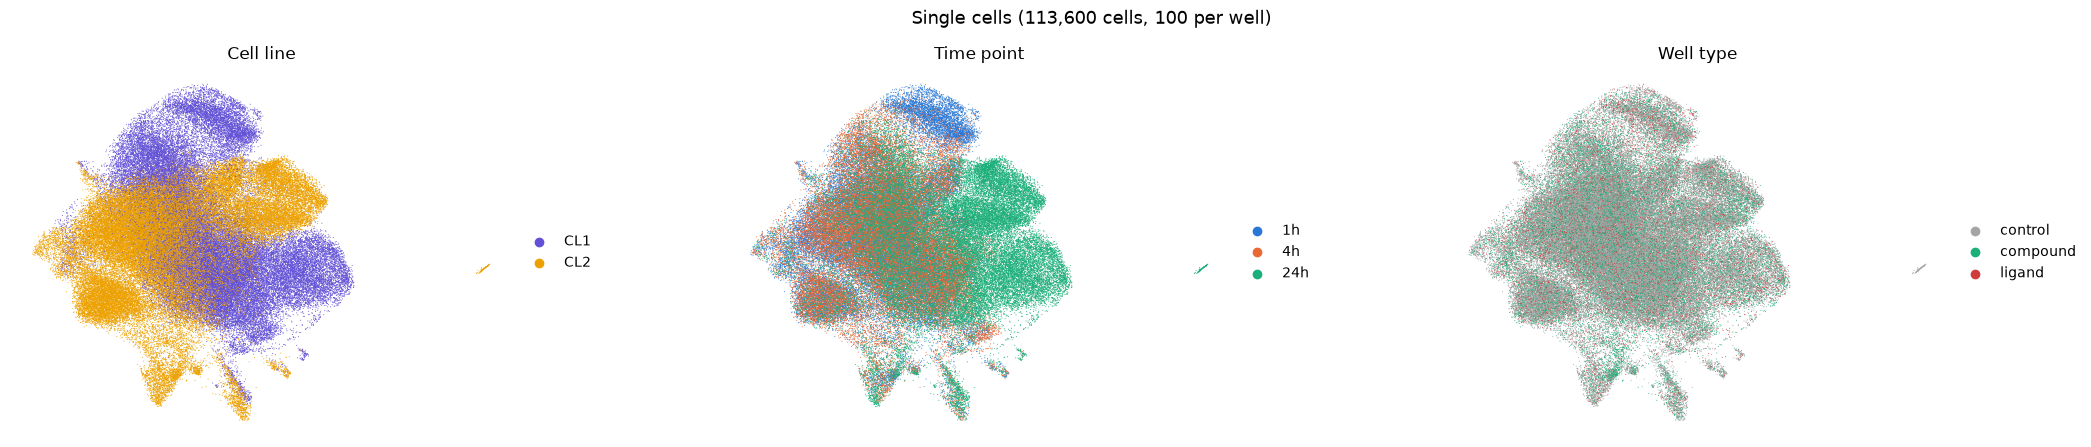

In [6]:
def set_colors(adata):
    """Use the same category order and colors as the QC notebooks."""
    for column, colors in [("Metadata_cell_line", line_colors), ("Metadata_time_point", plate_colors), ("Metadata_well_type", well_type_colors)]:
        adata.obs[column] = adata.obs[column].astype(str).astype("category").cat.reorder_categories(list(colors))
        adata.uns[f"{column}_colors"] = list(colors.values())


def plot_umap(adata, title, size, file_name):
    """Draw one UMAP, colored by cell line, time point and well type."""
    set_colors(adata)
    axes = sc.pl.umap(
        adata,
        color=["Metadata_cell_line", "Metadata_time_point", "Metadata_well_type"],
        title=["Cell line", "Time point", "Well type"],
        size=size,
        ncols=3,
        wspace=0.3,
        frameon=False,
        show=False,
    )
    plt.suptitle(title, y=1.02, fontsize=13)
    plt.savefig(figures_dir / file_name, dpi=200, bbox_inches="tight")
    plt.show()


plot_umap(sc_sample, f"Single cells ({sc_sample.n_obs:,} cells, {cells_per_well} per well)", size=2, file_name="01_umap_single-cells.png")

**Result:** cells group first by cell line, then by time point: cells at 24h separate from cells at 1h and 4h, which overlap. Control, compound and ligand cells mix everywhere, so treatment effects are small compared with the differences between single cells.

## 5. Well UMAP

Each dot is one well profile. The last panel shows the treatments: DMSO, the 5 compounds and the 2 ligands, with all doses together.

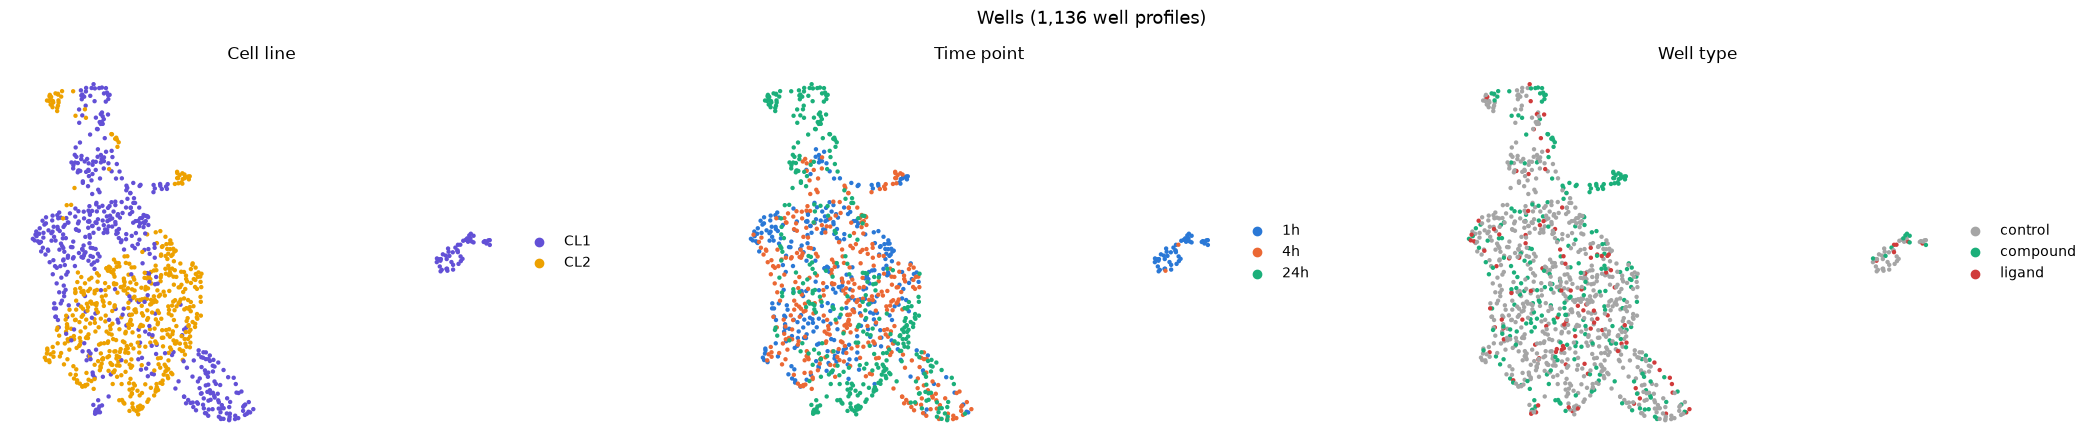

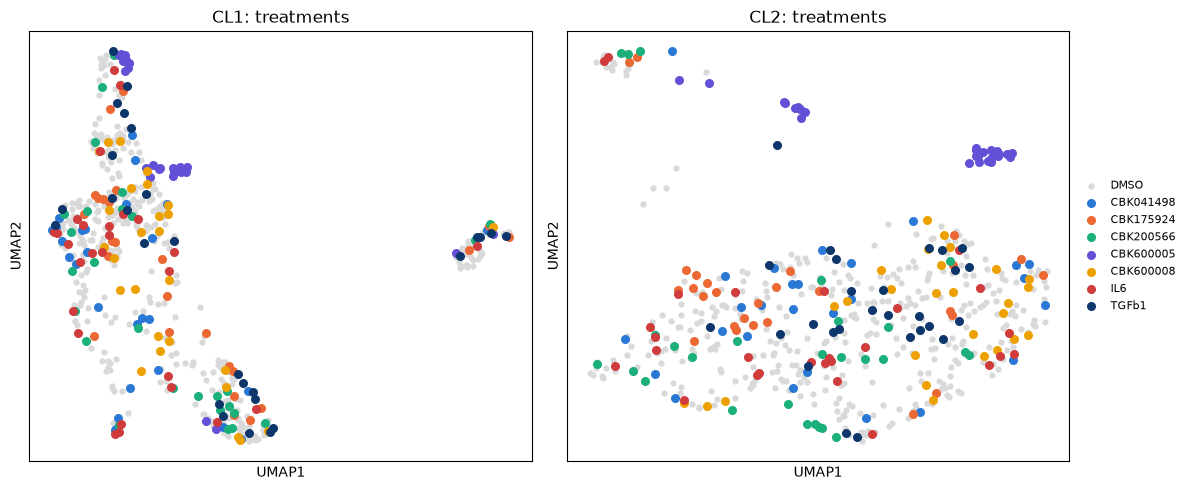

In [7]:
plot_umap(agg_profiles, f"Wells ({agg_profiles.n_obs:,} well profiles)", size=40, file_name="02_umap_wells.png")

# the treatments, one panel per cell line, since the cell lines sit apart
treatments = sorted(set(agg_profiles.obs["Metadata_treatment"].astype(str)) - {"DMSO"})
treatment_colors = dict(zip(["DMSO", *treatments], ["#d9d9d9", "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100", "#d03b3b", "#0d366b"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
umap = agg_profiles.obsm["X_umap"]
for ax, line in zip(axes, line_colors):
    in_line = (agg_profiles.obs["Metadata_cell_line"] == line).to_numpy()
    for treatment, color in treatment_colors.items():
        chosen = in_line & (agg_profiles.obs["Metadata_treatment"].astype(str) == treatment).to_numpy()
        ax.scatter(*umap[chosen].T, s=12 if treatment == "DMSO" else 30, color=color, label=treatment, zorder=1 if treatment == "DMSO" else 2)
    ax.set(title=f"{line}: treatments", xlabel="UMAP1", ylabel="UMAP2", xticks=[], yticks=[])
axes[1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(figures_dir / "03_umap_wells_treatments.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:**

- Each cell line is normalized to its own DMSO wells, so the two lines overlap in the well map.
- A group of 49 CL1 wells forms its own island: 47 from 1h and 2 from 4h. It holds DMSO wells as well as treated wells, so it is not a treatment effect (section 6). The 24h wells of both lines also spread into arms.
- Treatments: CBK600005 forms its own tight groups, in CL2 at every time point and in CL1 mainly at 24h. The other treatments, CBK200566 included, mix with DMSO or with wells from the same area of the plate.

## 6. What separates the well arms?

Every well is normalized against the DMSO wells of its own plate and cell line. So DMSO wells that sit far from the center of the map differ from the other DMSO wells of the same plate. That points to an effect inside the plate, such as the number of cells in a well, or its position on the plate.

We first color the well map by cell count and plate position. Then we test the DMSO wells directly. They all received the same treatment, so within a plate and cell line they should look alike. For each DMSO well, we measure how far it lies from the typical DMSO well of its plate and cell line (in PCA space, which keeps distances better than UMAP), and test whether that distance follows:

- **an unusual cell count:** how far the well's cell count is from the plate's typical count, in either direction;
- **the plate edge:** how many wells lie between the well and the nearest edge of the plate.

We use rank (Spearman) correlations, from -1 to 1. A clear positive correlation with an unusual cell count, or a clear negative correlation with the distance to the edge, means a technical effect.

**Pass if:** the correlations stay close to 0 (below about 0.3).

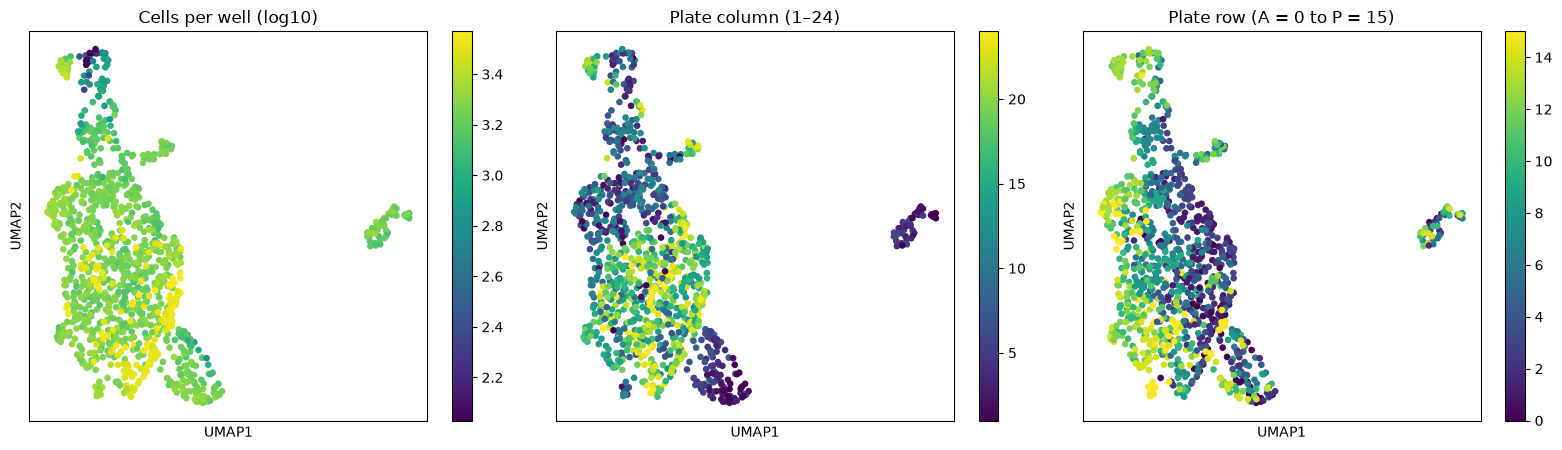

DMSO wells: rank correlation of the distance from the typical DMSO well with ...
shape: (6, 5)
┌────────────────────┬─────────────────────┬────────────┬─────────────────┬─────────────────┐
│ Metadata_cell_line ┆ Metadata_time_point ┆ DMSO wells ┆ vs unusual cell ┆ vs wells to the │
│ ---                ┆ ---                 ┆ ---        ┆ count           ┆ plate edge      │
│ str                ┆ str                 ┆ i64        ┆ ---             ┆ ---             │
│                    ┆                     ┆            ┆ f64             ┆ f64             │
╞════════════════════╪═════════════════════╪════════════╪═════════════════╪═════════════════╡
│ CL1                ┆ 1h                  ┆ 127        ┆ 0.31            ┆ -0.25           │
│ CL1                ┆ 4h                  ┆ 127        ┆ 0.3             ┆ -0.19           │
│ CL1                ┆ 24h                 ┆ 125        ┆ 0.59            ┆ -0.28           │
│ CL2                ┆ 1h                  ┆ 127        ┆ 0

In [8]:
# what separates the arms of the well UMAP? color the wells by cell count and by plate position
obs = agg_profiles.obs
umap = agg_profiles.obsm["X_umap"]
row_number = obs["Metadata_Row"].astype(str).map("ABCDEFGHIJKLMNOP".index).to_numpy()
panels = [
    ("Cells per well (log10)", np.log10(obs["Metadata_CellCount"].astype(float).to_numpy())),
    ("Plate column (1–24)", obs["Metadata_Column"].astype(int).to_numpy()),
    ("Plate row (A = 0 to P = 15)", row_number),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (title, values) in zip(axes, panels):
    points = ax.scatter(*umap.T, c=values, s=14, cmap="viridis")
    fig.colorbar(points, ax=ax)
    ax.set(title=title, xlabel="UMAP1", ylabel="UMAP2", xticks=[], yticks=[])
plt.tight_layout()
plt.savefig(figures_dir / "04_umap_wells_cell-count-and-position.png", dpi=200, bbox_inches="tight")
plt.show()

# the DMSO wells of a plate and cell line got the same treatment, so they should all look alike;
# for each DMSO well: how far is it from the typical DMSO well of its plate and cell line, in PCA space?
pcs = agg_profiles.obsm["X_pca"]
is_dmso = (obs["Metadata_Control_Type"] == "negcon").to_numpy()
log_count = np.log2(obs["Metadata_CellCount"].astype(float).to_numpy())
column_number = obs["Metadata_Column"].astype(int).to_numpy()
wells_to_edge = np.minimum.reduce([row_number, 15 - row_number, column_number - 1, 24 - column_number])


def rank_correlation(a, b):
    """Spearman correlation: the Pearson correlation of the ranks."""
    return round(float(np.corrcoef(pl.Series(a).rank(), pl.Series(b).rank())[0, 1]), 2)


rows = []
for (line, time), index in obs.groupby(["Metadata_cell_line", "Metadata_time_point"], observed=True).indices.items():
    dmso = index[is_dmso[index]]
    distance = np.linalg.norm(pcs[dmso] - np.median(pcs[dmso], axis=0), axis=1)
    unusual_count = np.abs(log_count[dmso] - np.median(log_count[dmso]))
    rows.append(
        {
            "Metadata_cell_line": str(line),
            "Metadata_time_point": str(time),
            "DMSO wells": len(dmso),
            "vs unusual cell count": rank_correlation(distance, unusual_count),
            "vs wells to the plate edge": rank_correlation(distance, wells_to_edge[dmso]),
        }
    )
print("DMSO wells: rank correlation of the distance from the typical DMSO well with ...")
print(pl.DataFrame(rows).sort("Metadata_cell_line", pl.col("Metadata_time_point").replace_strict({t: i for i, t in enumerate(plate_order)}, return_dtype=pl.Int64)))


**Result: WARN for cell count, PASS for plate edges.**

- In every plate and cell line, DMSO wells with an unusual number of cells look more different from the other DMSO wells (rank correlation 0.30–0.59). The effect is strongest at 24h (CL1 0.59, CL2 0.53), where cell numbers vary most.
- Distance to the plate edge has little effect (rank correlation -0.28 to 0.14).
- The island of CL1 wells holds every well in the odd rows (A, C, E … O) of columns 1–6 at 1h (47 wells, 33 of them DMSO), and 2 wells of the same area at 4h. This pattern points to dispensing or handling, not to biology.
- So cell density is a technical factor: compare wells with similar cell counts, or correct for cell count, in later analyses.

## 7. Save the UMAP coordinates

We save the UMAP coordinates with the metadata, so other notebooks can plot them without running this one again.

In [9]:
for adata, name in [(sc_sample, "qced_sc-sample"), (agg_profiles, "qced_wells")]:
    metadata_columns = [column for column in adata.obs.columns if column.startswith("Metadata_")]
    table = pl.from_pandas(adata.obs[metadata_columns].astype(str).reset_index(drop=True)).with_columns(
        pl.Series("UMAP1", adata.obsm["X_umap"][:, 0]), pl.Series("UMAP2", adata.obsm["X_umap"][:, 1])
    )
    path = results_dir / f"umap_{name}.parquet"
    table.write_parquet(path)
    print(f"{path.name}: {table.height:,} rows")

umap_qced_sc-sample.parquet: 113,600 rows
umap_qced_wells.parquet: 1,136 rows


## Summary

- **Data:** the QCed profiles: 1,136 well profiles (4 wells fail well QC), and a sample of 113,600 single cells (100 per well), with 1,399 features.
- **Method:** values clipped to ±20, PCA to 95% of the variance, then UMAP.
- **Biology:** cell line and time point drive the largest differences. CBK600005 stands apart from DMSO in both cell lines.
- **Technical effects:** cell density affects the profiles, most at 24h (DMSO rank correlation up to 0.59). The CL1 wells at 1h in the odd rows of columns 1–6 (47 wells) form their own group, which points to dispensing or handling. Plate edges in general have little effect.
- **Output:** UMAP coordinates in `results/umap_qced_*.parquet`, and figures in `results/figures/01.batch-effects-diagnosis/`.